## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Works when launched from either the repository root or notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "experiments/matched_inference/evaluation/matched_summary.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "experiments/matched_inference/evaluation/matched_summary.csv").exists(), "Run evaluate_matched.py first, and open notebook from repository root or notebooks/"
EVAL = ROOT / "experiments/matched_inference/evaluation"
FIGURES = ROOT / "experiments/matched_inference/figures"
TABLES = EVAL / "clean_tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
FIELDS = ["load_number", "pickup_location", "pickup_time", "dropoff_location", "dropoff_time", "total_rate", "rate_per_mile"]
LABELS = {"qwen_vlm":"Qwen-VLM", "paddle_llm_p2":"PaddleOCR + LLM P2", "regex_tesseract":"Regex + Tesseract", "doctr_llm_p2":"DocTR + LLM P2", "tesseract_llm_p2":"Tesseract + LLM P2", "tesseract_llm_p1":"Tesseract + LLM P1", "openocr_llm_p2":"OpenOCR + LLM P2", "easyocr_llm_p2":"EasyOCR + LLM P2"}
sns.set_theme(style="white", font_scale=0.95)
print("Repository:", ROOT)
print("Figures:", FIGURES)

Repository: /root/lorex-ocr-llm-experiments
Figures: /root/lorex-ocr-llm-experiments/experiments/matched_inference/figures


In [2]:
summary_all = pd.read_csv(EVAL / "matched_summary.csv")
per_field_all = pd.read_csv(EVAL / "matched_per_field.csv")
assert len(summary_all) == 8 and len(per_field_all) == 56
assert set(summary_all.method) == set(LABELS)
assert set(per_field_all.field) == set(FIELDS)
assert (summary_all.n == 135).all()
print("Methods:", len(summary_all), "| Per-field rows:", len(per_field_all), "| Documents per method: 135")
display(summary_all[["method", "n", "historical_clean_f1", "matched_clean_f1", "noisy_f1"]].sort_values("matched_clean_f1", ascending=False).round(2))

Methods: 8 | Per-field rows: 56 | Documents per method: 135


,method,n,historical_clean_f1,matched_clean_f1,noisy_f1
7,qwen_vlm,135,72.20,81.48,79.97
3,paddle_llm_p2,135,65.69,68.79,68.43
0,regex_tesseract,135,52.41,51.12,42.17
5,doctr_llm_p2,135,44.79,48.72,44.81
2,tesseract_llm_p2,135,39.50,42.51,35.22
6,openocr_llm_p2,135,25.61,31.43,33.23
1,tesseract_llm_p1,135,30.26,27.51,23.27
4,easyocr_llm_p2,135,9.96,11.67,9.80


In [3]:
metric_cols = {"exact_match":"Exact Match", "f1":"F1 Score", "fuzzy_score":"Fuzzy Score", "lev_similarity":"Levenshtein Similarity"}
all_eval = per_field_all[["method", "field"] + [f"matched_clean_{m}" for m in metric_cols]].copy()
all_eval = all_eval.rename(columns={f"matched_clean_{m}":m for m in metric_cols})
all_eval["method_label"] = all_eval.method.map(LABELS)
all_eval["field"] = pd.Categorical(all_eval.field, categories=FIELDS, ordered=True)
display(all_eval.sort_values(["method", "field"]).head(14).round(2))
all_eval.to_csv(TABLES / "matched_clean_per_field.csv", index=False)

,method,field,exact_match,f1,fuzzy_score,lev_similarity,method_label
35,doctr_llm_p2,load_number,57.78,57.78,93.33,92.77,DocTR + LLM P2
36,doctr_llm_p2,pickup_location,16.30,16.30,81.32,77.78,DocTR + LLM P2
37,doctr_llm_p2,pickup_time,56.30,56.30,93.03,92.11,DocTR + LLM P2
38,doctr_llm_p2,dropoff_location,27.41,27.51,88.82,85.11,DocTR + LLM P2
39,doctr_llm_p2,dropoff_time,61.48,61.48,94.36,93.28,DocTR + LLM P2
40,doctr_llm_p2,total_rate,43.70,43.87,89.06,86.71,DocTR + LLM P2
41,doctr_llm_p2,rate_per_mile,77.78,77.78,98.45,97.18,DocTR + LLM P2
28,easyocr_llm_p2,load_number,42.22,42.22,90.73,90.39,EasyOCR + LLM P2
29,easyocr_llm_p2,pickup_location,8.15,8.15,73.77,70.82,EasyOCR + LLM P2
30,easyocr_llm_p2,pickup_time,0.74,0.74,76.80,72.63,EasyOCR + LLM P2


In [4]:
def make_pivot(metric):
    return all_eval.pivot(index="method", columns="field", values=metric).reindex(columns=FIELDS)

def sorted_heatmap(metric, title, filename, cmap="YlGnBu"):
    pivot = make_pivot(metric)
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
    pivot.index = pivot.index.map(LABELS)
    fig, ax = plt.subplots(figsize=(13.5, 6.2))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap=cmap, vmin=0, vmax=100,
                linewidths=0.4, linecolor="white", cbar_kws={"label":"Score (%)"}, ax=ax)
    ax.set_title(title, fontsize=13, pad=14)
    ax.set_xlabel("Field")
    ax.set_ylabel("Method")
    ax.tick_params(axis="x", rotation=28)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{filename}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()
    return pivot

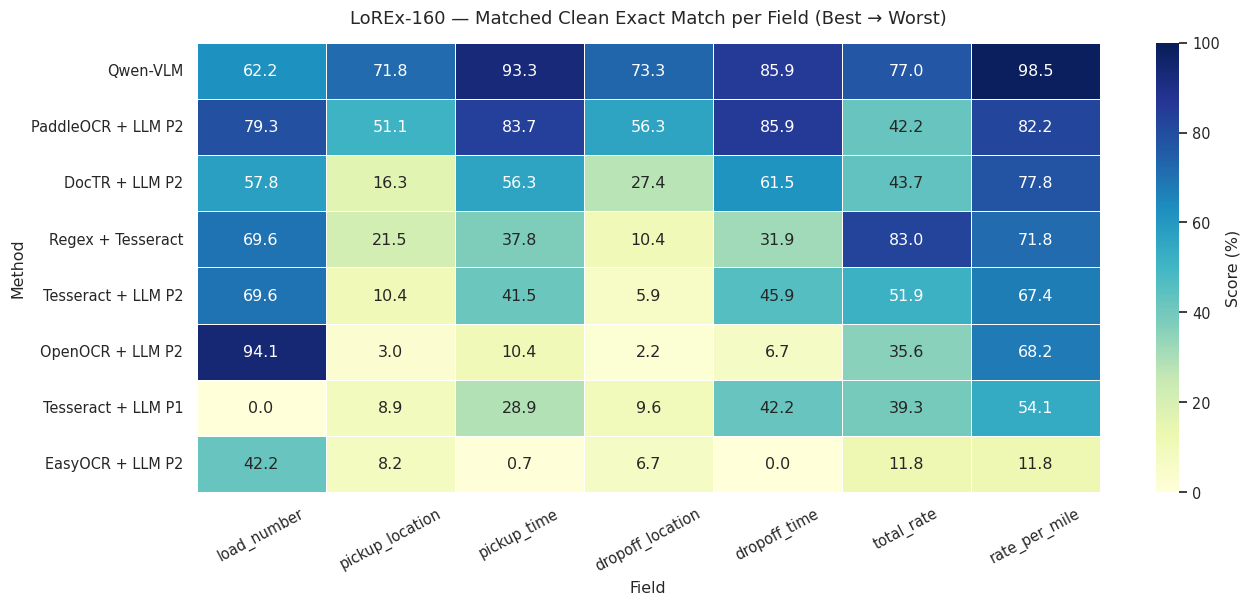

field,load_number,pickup_location,pickup_time,dropoff_location,dropoff_time,total_rate,rate_per_mile
method,,,,,,,
Qwen-VLM,62.22,71.85,93.33,73.33,85.93,77.04,98.52
PaddleOCR + LLM P2,79.26,51.11,83.70,56.30,85.93,42.22,82.22
DocTR + LLM P2,57.78,16.30,56.30,27.41,61.48,43.70,77.78
Regex + Tesseract,69.63,21.48,37.78,10.37,31.85,82.96,71.85
Tesseract + LLM P2,69.63,10.37,41.48,5.93,45.93,51.85,67.41
OpenOCR + LLM P2,94.07,2.96,10.37,2.22,6.67,35.56,68.15
Tesseract + LLM P1,0.00,8.89,28.89,9.63,42.22,39.26,54.07
EasyOCR + LLM P2,42.22,8.15,0.74,6.67,0.00,11.85,11.85


In [5]:
pivot_exact_sorted = sorted_heatmap("exact_match", "LoREx-160 — Matched Clean Exact Match per Field (Best → Worst)", "fig14_matched_clean_exact_match")
display(pivot_exact_sorted.round(2))

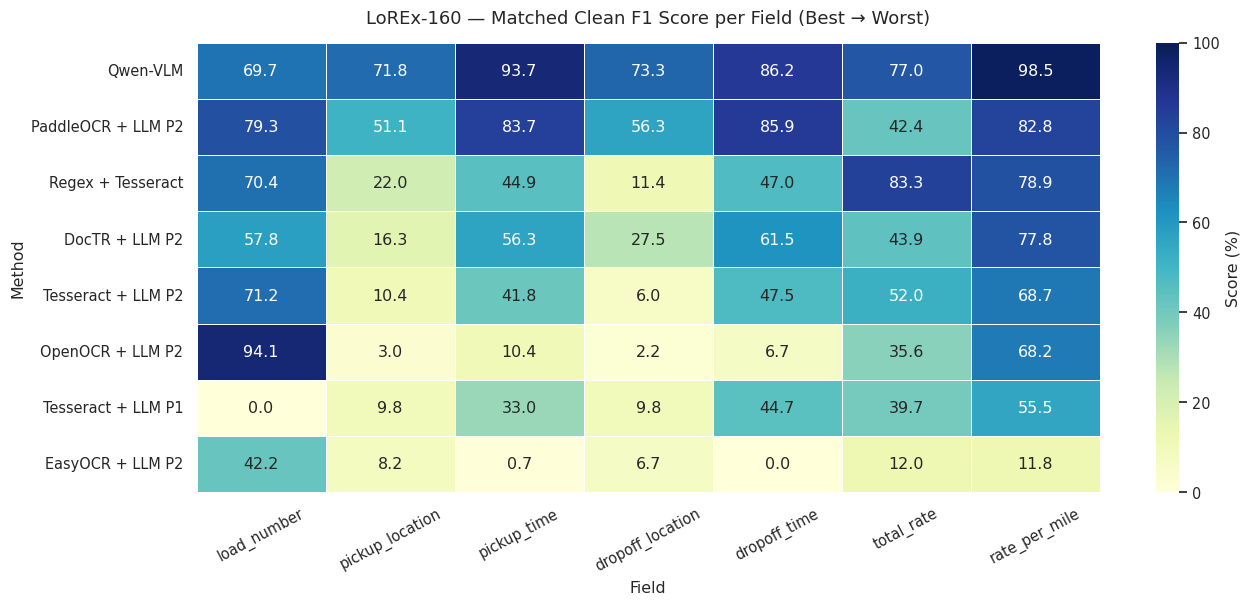

field,load_number,pickup_location,pickup_time,dropoff_location,dropoff_time,total_rate,rate_per_mile
method,,,,,,,
Qwen-VLM,69.71,71.85,93.68,73.33,86.25,77.04,98.52
PaddleOCR + LLM P2,79.26,51.11,83.70,56.30,85.93,42.38,82.84
Regex + Tesseract,70.41,21.97,44.93,11.38,46.99,83.27,78.86
DocTR + LLM P2,57.78,16.30,56.30,27.51,61.48,43.87,77.78
Tesseract + LLM P2,71.21,10.37,41.79,5.95,47.51,52.04,68.68
OpenOCR + LLM P2,94.07,2.96,10.37,2.22,6.67,35.56,68.15
Tesseract + LLM P1,0.00,9.80,33.05,9.81,44.71,39.70,55.51
EasyOCR + LLM P2,42.22,8.15,0.74,6.67,0.00,12.03,11.85


In [6]:
pivot_f1_sorted = sorted_heatmap("f1", "LoREx-160 — Matched Clean F1 Score per Field (Best → Worst)", "fig15_matched_clean_f1")
display(pivot_f1_sorted.round(2))

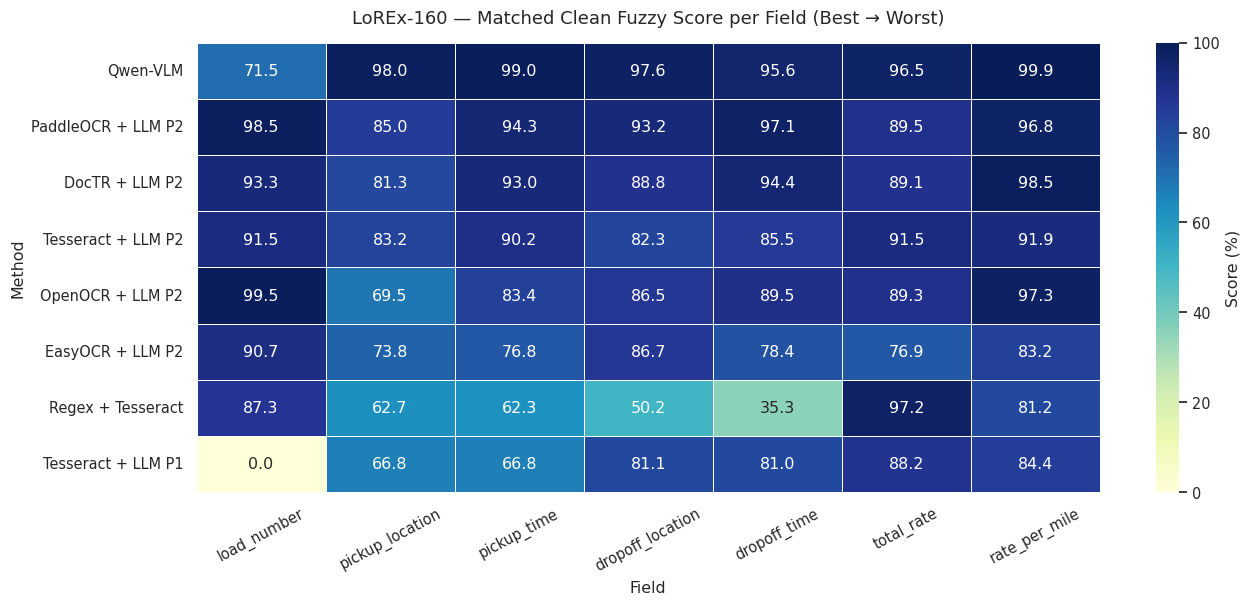

In [7]:
pivot_fuzzy_sorted = sorted_heatmap("fuzzy_score", "LoREx-160 — Matched Clean Fuzzy Score per Field (Best → Worst)", "fig16_matched_clean_fuzzy")

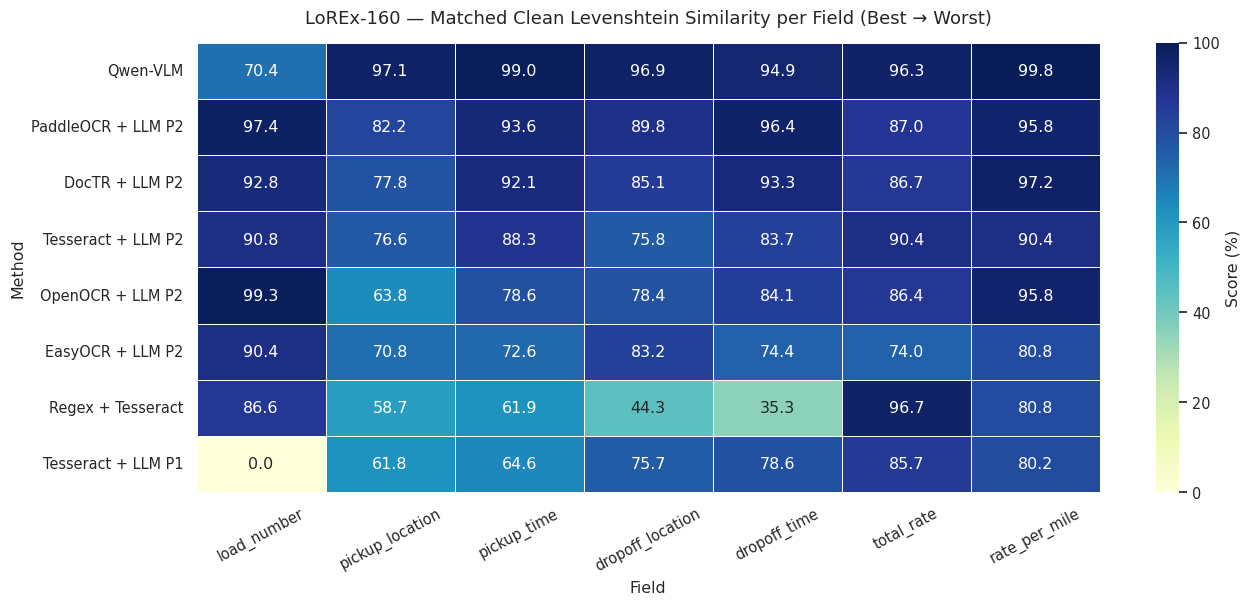

In [8]:
pivot_lev_sorted = sorted_heatmap("lev_similarity", "LoREx-160 — Matched Clean Levenshtein Similarity per Field (Best → Worst)", "fig17_matched_clean_lev_similarity")

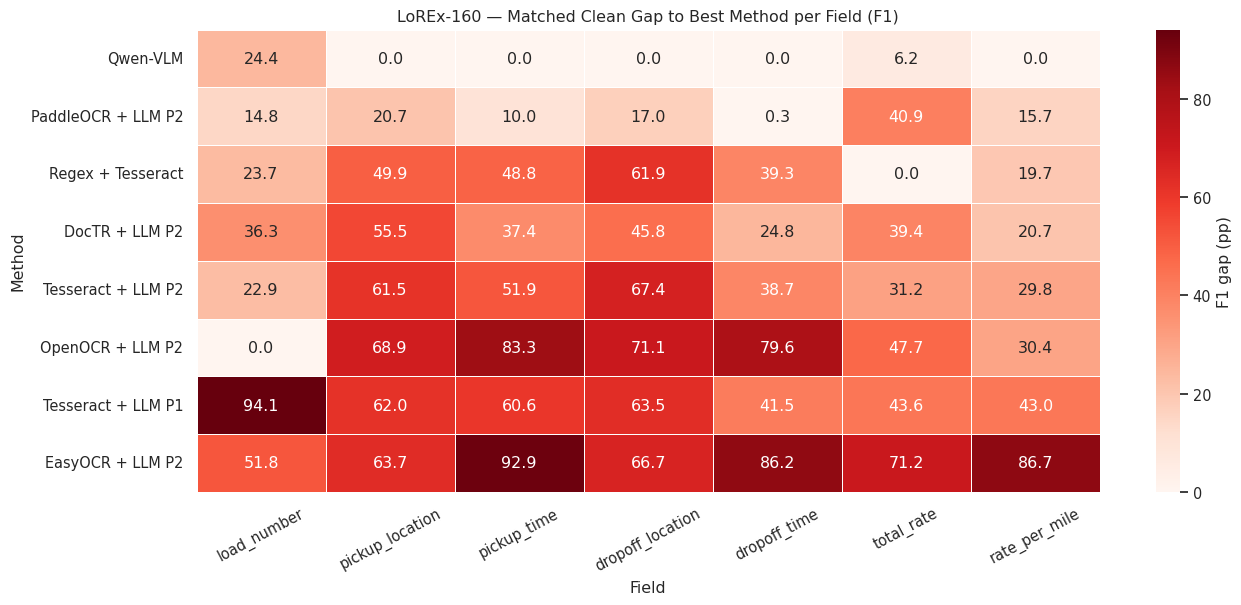

In [9]:
pivot_f1 = make_pivot("f1")
best_per_field = pivot_f1.max(axis=0)
gap = best_per_field - pivot_f1
gap = gap.loc[gap.mean(axis=1).sort_values().index]
gap.index = gap.index.map(LABELS)
fig, ax = plt.subplots(figsize=(13.5, 6.2))
sns.heatmap(gap, annot=True, fmt=".1f", cmap="Reds", vmin=0,
            linewidths=0.4, linecolor="white", cbar_kws={"label":"F1 gap (pp)"}, ax=ax)
ax.set_title("LoREx-160 — Matched Clean Gap to Best Method per Field (F1)")
ax.set_xlabel("Field"); ax.set_ylabel("Method"); ax.tick_params(axis="x", rotation=28)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(FIGURES / f"matched_clean_gap_to_best.{ext}", dpi=300, bbox_inches="tight")
plt.show()
gap.to_csv(TABLES / "matched_clean_gap_to_best.csv")

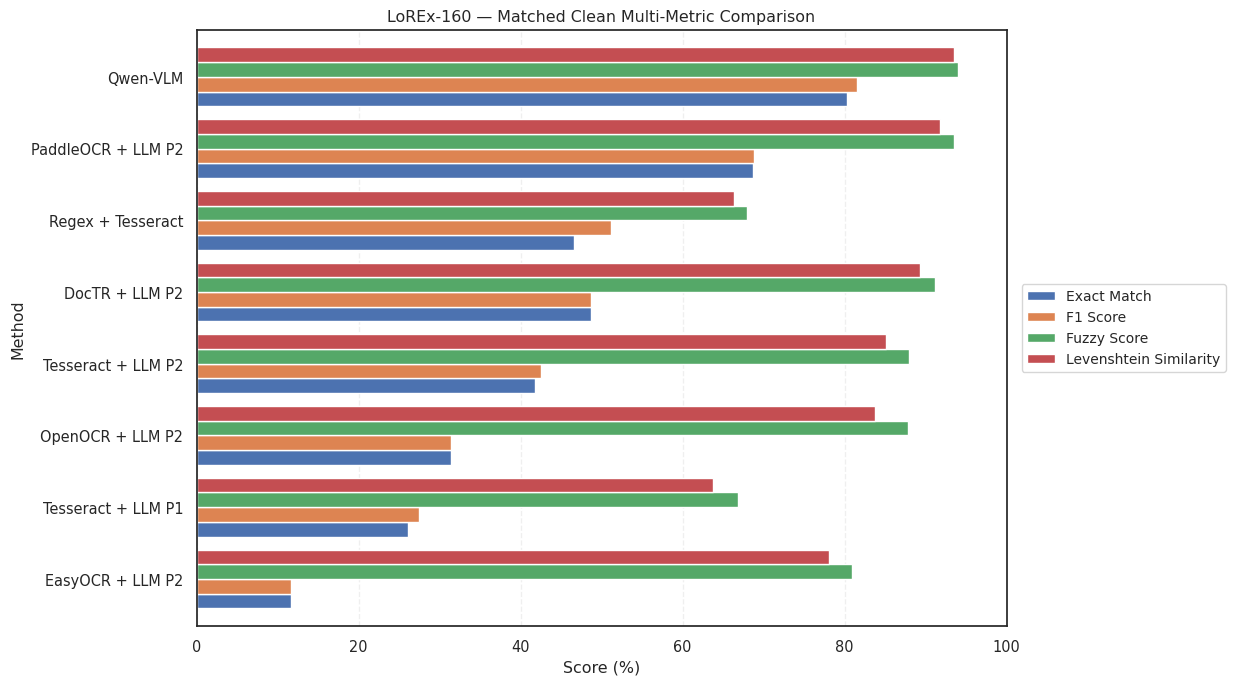

,Exact Match,F1 Score,Fuzzy Score,Levenshtein Similarity
method,,,,
Qwen-VLM,80.32,81.48,94.01,93.49
PaddleOCR + LLM P2,68.68,68.79,93.48,91.74
Regex + Tesseract,46.56,51.12,68.02,66.32
DocTR + LLM P2,48.68,48.72,91.19,89.28
Tesseract + LLM P2,41.80,42.51,88.01,85.13
OpenOCR + LLM P2,31.43,31.43,87.88,83.78
Tesseract + LLM P1,26.14,27.51,66.89,63.79
EasyOCR + LLM P2,11.64,11.67,80.94,78.04


In [14]:
summary = summary_all.set_index("method")[[f"matched_clean_{m}" for m in metric_cols]].copy()
summary.columns = [metric_cols[m] for m in metric_cols]
summary = summary.sort_values("F1 Score", ascending=True)
summary.index = summary.index.map(LABELS)
fig, ax = plt.subplots(figsize=(12.5, 7))
summary.plot(kind="barh", ax=ax, width=0.82)
ax.set_title("LoREx-160 — Matched Clean Multi-Metric Comparison")
ax.set_xlabel("Score (%)"); ax.set_ylabel("Method"); ax.set_xlim(0, 100)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=True,
    fontsize=10
)

fig.tight_layout()
ax.grid(axis="x", linestyle="--", alpha=0.3)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(FIGURES / f"matched_clean_multi_metric_summary.{ext}", dpi=300, bbox_inches="tight")
plt.show()
display(summary.iloc[::-1].round(2))
summary.to_csv(TABLES / "matched_clean_macro_summary.csv")

In [11]:
paper_table = summary_all[["method", "n", "matched_clean_exact_match", "matched_clean_f1", "matched_clean_fuzzy_score", "matched_clean_lev_similarity"]].copy()
paper_table = paper_table.sort_values("matched_clean_f1", ascending=False)
paper_table["method"] = paper_table.method.map(LABELS)
paper_table.columns = ["Method", "N", "Exact Match (%)", "F1 (%)", "Fuzzy Score (%)", "Levenshtein Similarity (%)"]
display(paper_table.round(2))
paper_table.to_csv(TABLES / "matched_clean_paper_table.csv", index=False)
print("Saved table:", TABLES / "matched_clean_paper_table.csv")
print("Figures exported to:", FIGURES)
assert len(paper_table) == 8
assert np.isfinite(paper_table.select_dtypes(include="number").to_numpy()).all()
assert paper_table["F1 (%)"].between(0, 100).all()

,Method,N,Exact Match (%),F1 (%),Fuzzy Score (%),Levenshtein Similarity (%)
7,Qwen-VLM,135,80.32,81.48,94.01,93.49
3,PaddleOCR + LLM P2,135,68.68,68.79,93.48,91.74
0,Regex + Tesseract,135,46.56,51.12,68.02,66.32
5,DocTR + LLM P2,135,48.68,48.72,91.19,89.28
2,Tesseract + LLM P2,135,41.80,42.51,88.01,85.13
6,OpenOCR + LLM P2,135,31.43,31.43,87.88,83.78
1,Tesseract + LLM P1,135,26.14,27.51,66.89,63.79
4,EasyOCR + LLM P2,135,11.64,11.67,80.94,78.04


Saved table: /root/lorex-ocr-llm-experiments/experiments/matched_inference/evaluation/clean_tables/matched_clean_paper_table.csv
Figures exported to: /root/lorex-ocr-llm-experiments/experiments/matched_inference/figures
